In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
sns.set_palette("colorblind")
pd.set_option('display.max_columns', 50)

In [3]:
df = pd.read_csv('/home/luka/Bureau/cours/4A/projet_fraude/data/processed/sampled_transactions.csv')

df['Amount'] = df['Amount'].str.replace('$', '', regex=False).astype('float32')

df['Year'] = df['Year'].astype('int16')
df['Month'] = df['Month'].astype('int8')
df['Day'] = df['Day'].astype('int8')
df['Card'] = df['Card'].astype('int8')

df['Zip'] = df['Zip'].astype('float32')

categorical_cols = ['Use Chip', 'Merchant City', 'Merchant State', 'Errors?', 'Is Fraud?']

for col in categorical_cols:
    df[col] = df[col].astype('category')

df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4692821 entries, 0 to 4692820
Data columns (total 15 columns):
 #   Column          Dtype   
---  ------          -----   
 0   User            int64   
 1   Card            int8    
 2   Year            int16   
 3   Month           int8    
 4   Day             int8    
 5   Time            object  
 6   Amount          float32 
 7   Use Chip        category
 8   Merchant Name   int64   
 9   Merchant City   category
 10  Merchant State  category
 11  Zip             float32 
 12  MCC             int64   
 13  Errors?         category
 14  Is Fraud?       category
dtypes: category(5), float32(2), int16(1), int64(3), int8(3), object(1)
memory usage: 439.4 MB


In [4]:
print(f"Lignes avant filtrage : {len(df)}")

df = df[df['Amount'] >= 0]

print(f"Lignes après filtrage : {len(df)}")

Lignes avant filtrage : 4692821
Lignes après filtrage : 4480314


In [6]:
date_str = (df['Year'].astype(str) + '-' + df['Month'].astype(str).str.zfill(2) + '-' + df['Day'].astype(str).str.zfill(2) + ' ' + df['Time'])
df['Datetime'] = pd.to_datetime(date_str)

0   2002-01-01 12:24:00
1   2002-01-01 16:47:00
2   2002-01-01 17:40:00
3   2002-01-01 21:59:00
4   2002-01-02 16:05:00
Name: Datetime, dtype: datetime64[ns]

In [11]:
df = df.sort_values(by=['User', 'Card', 'Datetime'])

df['Time_Since_Last_Trans'] = df.groupby(['User', 'Card'])['Datetime'].diff().dt.total_seconds()

df['Time_Since_Last_Trans'] = df['Time_Since_Last_Trans'].fillna(0)

utilisateur_test = df['User'].iloc[0]
print(f"Transactions pour l'utilisateur n° {utilisateur_test}")

display(df[(df['User'] == utilisateur_test) & (df['Card'] == 0)][['User', 'Card', 'Datetime', 'Amount', 'Time_Since_Last_Trans']].head(10))

Transactions pour l'utilisateur n° 5


,User,Card,Datetime,Amount,Time_Since_Last_Trans
0,5,0,2002-01-01 12:24:00,45.610001,0.0
1,5,0,2002-01-01 16:47:00,40.000000,15780.0
2,5,0,2002-01-01 17:40:00,108.529999,3180.0
3,5,0,2002-01-01 21:59:00,26.160000,15540.0
4,5,0,2002-01-02 16:05:00,60.000000,65160.0
5,5,0,2002-01-02 16:51:00,60.000000,2760.0
6,5,0,2002-01-02 17:54:00,99.360001,3780.0
7,5,0,2002-01-03 17:29:00,40.000000,84900.0
8,5,0,2002-01-03 17:49:00,80.720001,1200.0
9,5,0,2002-01-04 10:58:00,16.370001,61740.0


In [12]:
df = df.set_index('Datetime')

df['Trans_Count_24h'] = df.groupby(['User', 'Card'])['Amount'].rolling('24h').count().values
df['Amt_Mean_7d'] = df.groupby(['User', 'Card'])['Amount'].rolling('7d').mean().values

df = df.reset_index()

display(df[['User', 'Datetime', 'Amount', 'Time_Since_Last_Trans', 'Trans_Count_24h', 'Amt_Mean_7d']].head(10))

,User,Datetime,Amount,Time_Since_Last_Trans,Trans_Count_24h,Amt_Mean_7d
0,5,2002-01-01 12:24:00,45.610001,0.0,1.0,45.610001
1,5,2002-01-01 16:47:00,40.000000,15780.0,2.0,42.805000
2,5,2002-01-01 17:40:00,108.529999,3180.0,3.0,64.713333
3,5,2002-01-01 21:59:00,26.160000,15540.0,4.0,55.075000
4,5,2002-01-02 16:05:00,60.000000,65160.0,4.0,56.060000
5,5,2002-01-02 16:51:00,60.000000,2760.0,4.0,56.716667
6,5,2002-01-02 17:54:00,99.360001,3780.0,4.0,62.808571
7,5,2002-01-03 17:29:00,40.000000,84900.0,2.0,59.957500
8,5,2002-01-03 17:49:00,80.720001,1200.0,3.0,62.264445
9,5,2002-01-04 10:58:00,16.370001,61740.0,3.0,57.675000


In [15]:
df['Time'].head()

0    12:24
1    16:47
2    17:40
3    21:59
4    16:05
Name: Time, dtype: object

In [16]:
df['Hour'] = df['Datetime'].dt.hour.astype('int8')

df['Is_Night_Risk'] = df['Hour'].between(2, 5).astype('int8')

high_risk_mccs = [5712, 5732, 5094, 7996, 3000, 3722, 5932, 3389, 5193, 4722, 3771, 3684, 3390, 3504, 3359]
df['Is_High_Risk_MCC'] = df['MCC'].isin(high_risk_mccs).astype('int8')


df['Amount_vs_Habit_Ratio'] = (df['Amount'] / (df['Amt_Mean_7d'] + 0.01)).astype('float32')


print("\nAperçu des nouvelles features :")
display(df[['Amount', 'Amt_Mean_7d', 'Amount_vs_Habit_Ratio', 'Hour', 'Is_Night_Risk', 'Is_High_Risk_MCC']].head())


Aperçu des nouvelles features :


,Amount,Amt_Mean_7d,Amount_vs_Habit_Ratio,Hour,Is_Night_Risk,Is_High_Risk_MCC
0,45.610001,45.610001,0.999781,12,0,0
1,40.000000,42.805000,0.934252,16,0,0
2,108.529999,64.713333,1.676830,17,0,0
3,26.160000,55.075000,0.474902,21,0,0
4,60.000000,56.060000,1.070091,16,0,0


In [17]:
df.head()

,Datetime,User,Card,Year,Month,Day,Time,Amount,Use Chip,Merchant Name,Merchant City,Merchant State,Zip,MCC,Errors?,Is Fraud?,Time_Since_Last_Trans,Trans_Count_24h,Amt_Mean_7d,Hour,Is_Night_Risk,Is_High_Risk_MCC,Amount_vs_Habit_Ratio
0,2002-01-01 12:24:00,5,0,2002,1,1,12:24,45.610001,Swipe Transaction,6576884879831183030,Davenport,IA,52803.0,4121,NaN,No,0.0,1.0,45.610001,12,0,0,0.999781
1,2002-01-01 16:47:00,5,0,2002,1,1,16:47,40.000000,Swipe Transaction,-4282466774399734331,Cedarburg,WI,53012.0,4829,NaN,No,15780.0,2.0,42.805000,16,0,0,0.934252
2,2002-01-01 17:40:00,5,0,2002,1,1,17:40,108.529999,Swipe Transaction,4665273507037692251,Davenport,IA,52803.0,5300,NaN,No,3180.0,3.0,64.713333,17,0,0,1.676830
3,2002-01-01 21:59:00,5,0,2002,1,1,21:59,26.160000,Swipe Transaction,6657473015144657322,Davenport,IA,52803.0,5813,NaN,No,15540.0,4.0,55.075000,21,0,0,0.474902
4,2002-01-02 16:05:00,5,0,2002,1,2,16:05,60.000000,Swipe Transaction,-4282466774399734331,Cedarburg,WI,53012.0,4829,NaN,No,65160.0,4.0,56.060000,16,0,0,1.070091


Préparation des matrices d'entraînement et de test
Année de test : 2020
Années d'entraînement : Avant 2020

Taille du jeu d'entraînement (Train) : 4417283 lignes
Taille du jeu de test (Test) : 63031 lignes
Taux de fraude dans le Train : 0.13%
Taux de fraude dans le Test : 0.00%


In [20]:
print("Séparation Train / Test (80/20)")
df_sorted = df.sort_values('Datetime')
split_idx = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_idx]
test_df = df_sorted.iloc[split_idx:]

X_train = train_df[features].copy()
y_train = train_df['Is Fraud?'].map({'No': 0, 'Yes': 1}).astype('int8')

X_test = test_df[features].copy()
y_test = test_df['Is Fraud?'].map({'No': 0, 'Yes': 1}).astype('int8')

X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
X_train.fillna(0, inplace=True)
X_test.fillna(0, inplace=True)

print(f"Taille Train : {len(X_train)} lignes | Taux de fraude : {y_train.mean()*100:.2f}%")
print(f"Taille Test  : {len(X_test)} lignes | Taux de fraude : {y_test.mean()*100:.2f}%")

Séparation Train / Test (80/20)
Taille Train : 3584251 lignes | Taux de fraude : 0.14%
Taille Test  : 896063 lignes | Taux de fraude : 0.11%


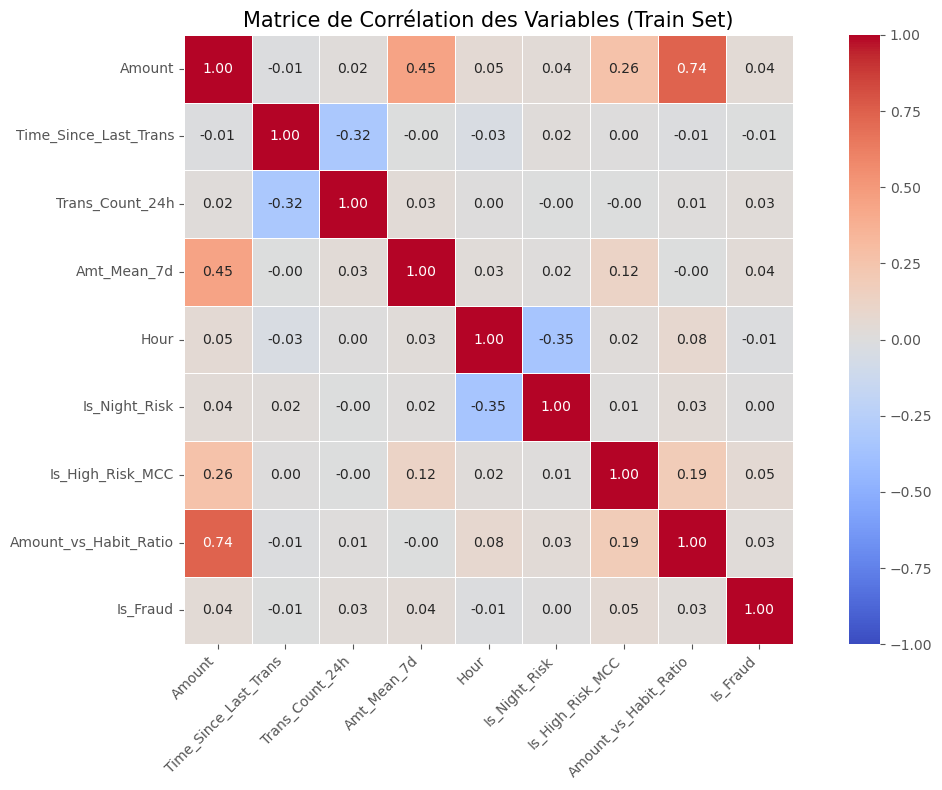

In [21]:
df_corr = X_train.copy()
df_corr['Is_Fraud'] = y_train

corr_matrix = df_corr.corr()


plt.figure(figsize=(12, 8))

sns.heatmap(corr_matrix, annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,linewidths=0.5,square=True)

plt.title("Matrice de Corrélation des Variables (Train Set)", fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

L'analyse de la matrice de corrélation indique que le jeu de données  est prêt pour la modélisation. Les relations introduites par le Feature Engineering se comportent normalement (ex: corrélation inverse entre la fréquence d'achat et le délai depuis la dernière transaction). La corrélation la plus prononcée s'établit à 0,74 entre le montant brut et le ratio comportemental des habitudes de dépense. Enfin, les corrélations extrêmement faibles avec la variable cible Is_Fraud (max 0,05) illustrent la nécessité d'utiliser des algorithmes et des méthodes d'évaluation spécifiques au risque.

AUPRC (Aire sous la courbe Precision-Recall) : 0.0034

              precision    recall  f1-score   support

Légitime (0)       1.00      0.81      0.90    895039
  Fraude (1)       0.00      0.41      0.00      1024

    accuracy                           0.81    896063
   macro avg       0.50      0.61      0.45    896063
weighted avg       1.00      0.81      0.89    896063



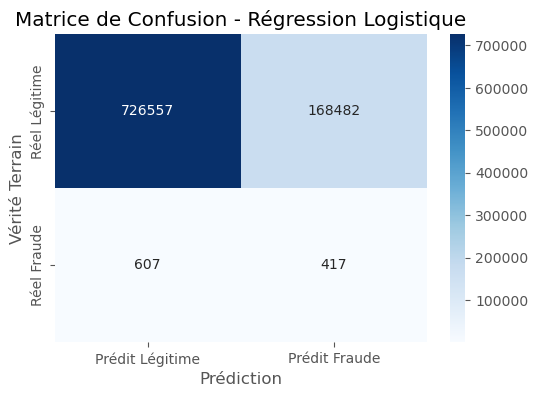

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)


y_pred = lr_model.predict(X_test_scaled)
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1] 

auprc = average_precision_score(y_test, y_prob)
print(f"AUPRC (Aire sous la courbe Precision-Recall) : {auprc:.4f}\n")

print(classification_report(y_test, y_pred, target_names=['Légitime (0)', 'Fraude (1)']))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Prédit Légitime', 'Prédit Fraude'],
            yticklabels=['Réel Légitime', 'Réel Fraude'])
plt.title("Matrice de Confusion - Régression Logistique")
plt.ylabel('Vérité Terrain')
plt.xlabel('Prédiction')
plt.show()

L'évaluation de ce modèle révèle un score AUPRC critique de 0.0034 et un mauvais score avec 168 482 faux positifs générés pour seulement 417 fraudes correctement identifiées, démontrant l'incapacité d'un modèle de séparation linéaire à traiter ce déséquilibre et justifiant le passage immédiat à un algorithme comme le Random Forest ou XGBoost.


AUPRC (Aire sous la courbe Precision-Recall) : 0.0036

              precision    recall  f1-score   support

Légitime (0)       1.00      0.88      0.94    895039
  Fraude (1)       0.00      0.37      0.01      1024

    accuracy                           0.88    896063
   macro avg       0.50      0.62      0.47    896063
weighted avg       1.00      0.88      0.93    896063



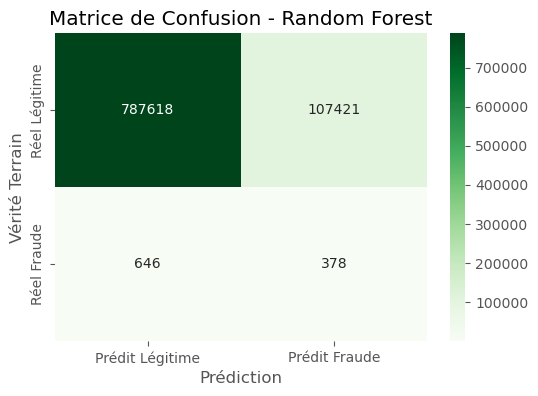


Top 5 des variables les plus importantes :


,Feature,Importance
3,Amt_Mean_7d,0.248291
0,Amount,0.194858
1,Time_Since_Last_Trans,0.186533
7,Amount_vs_Habit_Ratio,0.114911
6,Is_High_Risk_MCC,0.094941


In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced_subsample', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

auprc_rf = average_precision_score(y_test, y_prob_rf)
print(f"AUPRC (Aire sous la courbe Precision-Recall) : {auprc_rf:.4f}\n")

print(classification_report(y_test, y_pred_rf, target_names=['Légitime (0)', 'Fraude (1)']))

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Prédit Légitime', 'Prédit Fraude'],
            yticklabels=['Réel Légitime', 'Réel Fraude'])
plt.title("Matrice de Confusion - Random Forest")
plt.ylabel('Vérité Terrain')
plt.xlabel('Prédiction')
plt.show()


feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 des variables les plus importantes :")
display(feature_importances.head())

Le passage à un modèle non linéaire (Random Forest) a permis de réduire le coût des faux positifs, passant d'environ 168 000 alertes inutiles à 107 421. Bien que ce gain de précision s'accompagne d'une légère baisse des fraudes interceptées (378 Vrais Positifs), la matrice de confusion démontre une meilleure capacité de l'algorithme à isoler les comportements normaux. Par ailleurs, l'extraction de l'importance des variables valide la stratégie de Feature Engineering : les indicateurs comportementaux (Amt_Mean_7d, Time_Since_Last_Trans, Amount_vs_Habit_Ratio) monopolisent le top 4 des critères de décision du modèle, surpassant les variables transactionnelles brutes.

Seuil de probabilité optimal trouvé : 0.8467


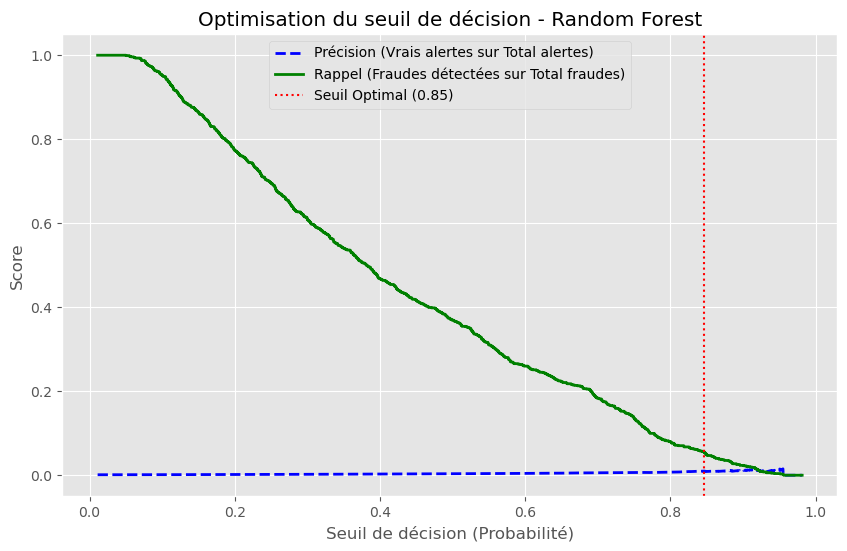

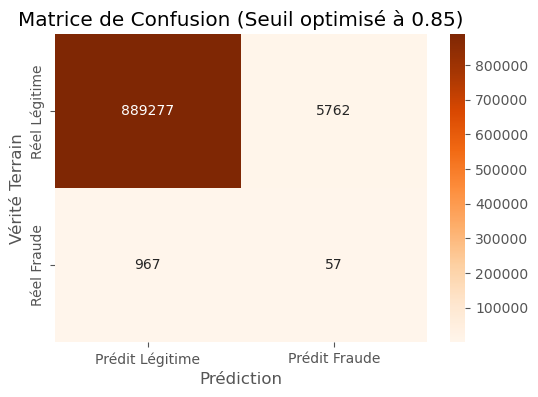

              precision    recall  f1-score   support

Légitime (0)       1.00      0.99      1.00    895039
  Fraude (1)       0.01      0.06      0.02      1024

    accuracy                           0.99    896063
   macro avg       0.50      0.52      0.51    896063
weighted avg       1.00      0.99      1.00    896063



In [27]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_rf)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]

print(f"Seuil de probabilité optimal trouvé : {optimal_threshold:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], "b--", label="Précision (Vrais alertes sur Total alertes)", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Rappel (Fraudes détectées sur Total fraudes)", linewidth=2)
plt.axvline(x=optimal_threshold, color='r', linestyle=':', label=f'Seuil Optimal ({optimal_threshold:.2f})')
plt.xlabel("Seuil de décision (Probabilité)")
plt.ylabel("Score")
plt.title("Optimisation du seuil de décision - Random Forest")
plt.legend(loc="best")
plt.grid(True)
plt.show()

y_pred_optimal = (y_prob_rf >= optimal_threshold).astype(int)

cm_optimal = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_optimal, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['Prédit Légitime', 'Prédit Fraude'],
            yticklabels=['Réel Légitime', 'Réel Fraude'])
plt.title(f"Matrice de Confusion (Seuil optimisé à {optimal_threshold:.2f})")
plt.ylabel('Vérité Terrain')
plt.xlabel('Prédiction')
plt.show()

print(classification_report(y_test, y_pred_optimal, target_names=['Légitime (0)', 'Fraude (1)']))

L'ajustement du seuil de probabilité à son niveau optimal théorique (0.85) démontre la flexibilité des modèles arborescents face au déséquilibre de classes. Ce seuil permet de réduire les faux positifs à un volume gérable sur le plan opérationnel (5 762 alertes bloquées à tort pour près de 900 000 transactions traitées), bien qu'il réduit le taux de détection (57 fraudes interceptées). Ce projet met en évidence que dans la détection de fraude financière, la performance n'est pas qu'une question d'algorithme (Régression Logistique vs Random Forest), mais surtout une question de Feature Engineering pertinent et d'alignement des seuils de prédiction avec les contraintes réelles.